# День 08. Упражнение 04
# Регрессия

## 0. Импорты

In [37]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
import joblib
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error


## 1. Предобработка

1. Прочитай файл [`checker_regression.csv`](https://drive.google.com/file/d/1L8auBzJEghWFewznhhFpcrqxW4GqcfRY/view?usp=sharing).
2. Заполни пропущенные значения нулями (`0`).
3. Раздели набор данных на обучающую и тестовую выборки с параметрами `test_size=0.2`.

In [38]:
checker_df = pd.read_csv("../data/checker_regression.csv")
checker_df = checker_df.fillna(0)
checker_df


,uid,num_commits,pageviews,AVG(diff)
0,user_1,62,28.0,0.00
1,user_1,62,28.0,0.00
2,user_1,62,28.0,0.00
3,user_1,62,28.0,0.00
4,user_1,62,28.0,0.00
...,...,...,...,...
72,user_31,128,0.0,-104.75
73,user_4,40,0.0,-175.60
74,user_6,15,0.0,-62.60
75,user_7,8,0.0,-115.50


In [39]:
X = checker_df.drop(columns=["AVG(diff)", "uid"])
y = checker_df["AVG(diff)"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=21
)

## 2. Кросс-валидация

1. Напиши функцию `crossval`, которая принимает аргументы: `n_splits` для `KFold()`, `X`, `y`, модель (инициализированный класс с параметрами модели; не забудь о `random_state=21`) и возвращает для данного класса модели результат в таком виде:

```
train - 2696.4496895424836 | test - 1589.9979527104958
train - 2660.957874001452 | test - 2075.102636027137
train - 2847.315529246795 | test - 320.911928168403
train - 2500.7691099659237 | test - 4132.461382030178
train - 2643.927917295123 | test - 2237.8140952197878
train - 2396.295678819444 | test - 4509.650064742476
train - 2003.402267924976 | test - 8403.491474908551
train - 2531.876094212613 | test - 3135.944102735099
train - 2683.1795186023123 | test - 1796.01426292594
train - 2537.1192483996338 | test - 3439.29824116941
Average RMSE on crossval is 3164.0686140637476
```

2. Запусти функцию для моделей `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`. Параметры можешь выбрать самостоятельно, но тщательно убедись, что они подходят.

In [40]:
"""

"""
def crossval(n_splits, X, y, model):
    kf = KFold(n_splits)
    kf_indexes = kf.split(X)
    rows = []
    for train_idx, val_idx in kf_indexes:
        train = X.iloc[train_idx] # Обучающие строки
        val = X.iloc[val_idx] # Проверочные строки
        y_train_fold = y.iloc[train_idx]
        y_val_fold = y.iloc[val_idx]
        model.fit(train, y_train_fold)
        pred1 = model.predict(train)
        pred2 = model.predict(val)
        err1 = root_mean_squared_error(y_train_fold, pred1)
        err2 = root_mean_squared_error(y_val_fold, pred2)
        rows.append(err2)
        print(f"train - {err1} | test - {err2}")
    print(f"Average RMSE on crossval is {sum(rows) / len(rows)}")


In [41]:
model = LinearRegression(fit_intercept=False)
crossval(10, X_train, y_train, model)

train - 50.91986428858255 | test - 15.543560378135172
train - 50.561768229765015 | test - 13.168008233741029
train - 46.049513856944884 | test - 64.71360347904273
train - 47.58082178454353 | test - 53.64130174522913
train - 50.525120799581366 | test - 15.01960725151505
train - 49.7041475530456 | test - 30.931779593053037
train - 50.24781213406287 | test - 22.732965965681277
train - 48.11127700121322 | test - 48.87663682262027
train - 45.61521431227999 | test - 68.09800360721137
train - 41.17966944754269 | test - 90.14741670275093
Average RMSE on crossval is 42.287288377898


In [42]:
model = DecisionTreeRegressor(max_depth=4, random_state=21)
crossval(10, X_train, y_train, model)


train - 19.321604440318826 | test - 0.0
train - 19.14514773560606 | test - 0.0
train - 16.806497661213168 | test - 45.60878935760811
train - 18.371167813129947 | test - 64.25542202226407
train - 15.825086528558495 | test - 39.90627039284261
train - 17.90617334248286 | test - 29.88069392336068
train - 19.14514773560606 | test - 0.0
train - 8.349123046148659 | test - 65.36707747565538
train - 10.731238973156357 | test - 81.3008040596201
train - 17.097454305332818 | test - 59.230669225248064
Average RMSE on crossval is 38.5549726456599


In [43]:
model = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=21)
crossval(10, X_train, y_train, model)


train - 19.037176241232533 | test - 0.0
train - 18.641503940266446 | test - 0.0
train - 17.110296704045236 | test - 34.110201867868696
train - 18.960813973269712 | test - 32.83755667879885
train - 16.406173531375497 | test - 37.07769894589329
train - 17.922235764032116 | test - 29.37563084552475
train - 18.94838554052666 | test - 0.0
train - 13.910593602234835 | test - 58.87912759633423
train - 15.337846092610365 | test - 51.03274499310922
train - 15.169345623368153 | test - 58.043258992259894
Average RMSE on crossval is 30.135621991978894


## 3. Предсказания и оценка

1. Сделай предсказания на тестовом наборе данных для каждой из трёх моделей с финальными параметрами.
2. Построй график для каждой модели, где по оси x — фактическая средняя разница, а по оси y — предсказание модели.
3. Как должен выглядеть график в идеальном случае? Напиши ответ в markdown-ячейке в конце раздела.

In [ ]:
linear_model = LinearRegression(fit_intercept=False)
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)
test_df = pd.DataFrame({
    "actual": y_test,
    "predicted": linear_pred
})
print("RMSE:", root_mean_squared_error(y_test, linear_pred))
test_df


RMSE: 57.41234356274978


,actual,predicted
3,0.0,-19.445491
19,-17.5,-7.995452
14,-48.5,-18.076674
45,-223.6,-12.862249
10,0.0,-0.253834
54,0.0,-9.642968
23,0.0,-14.191513
29,0.0,-1.512342
24,0.0,-14.191513
13,-89.0,-29.896038


<prediction cell 16>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


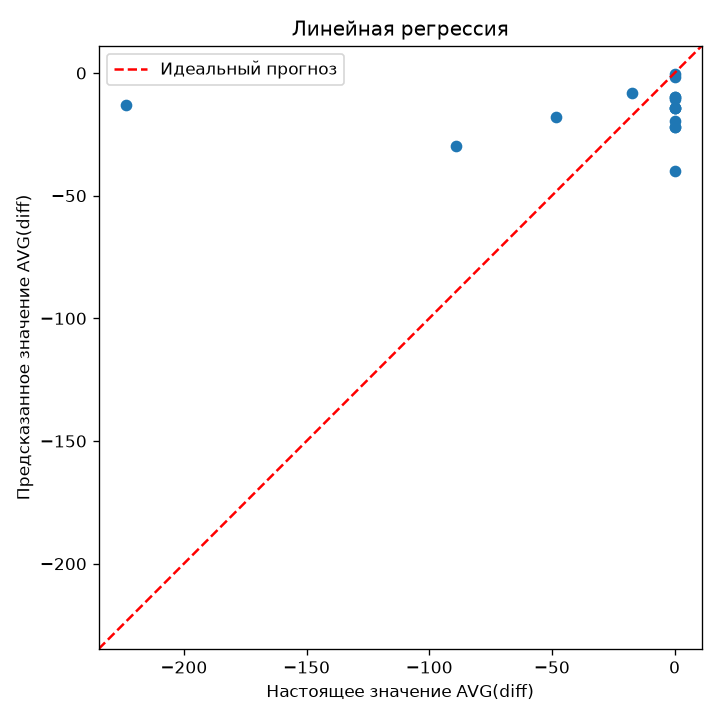

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(test_df["actual"], test_df["predicted"])
plt.xlabel("Настоящее значение AVG(diff)")
plt.ylabel("Предсказанное значение AVG(diff)")
plt.title("Линейная регрессия")

# Общие границы осей для всех трёх графиков
limits = [min(y.min(), linear_pred.min()), max(y.max(), linear_pred.max())]
margin = (limits[1] - limits[0]) * 0.05
limits = [limits[0] - margin, limits[1] + margin]
plt.plot(limits, limits, "r--", label="Идеальный прогноз")
plt.xlim(limits)
plt.ylim(limits)
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
tree_model = DecisionTreeRegressor(max_depth=4, random_state=21)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
tree_test_df = pd.DataFrame({
    "actual": y_test,
    "predicted": tree_pred
})
print("RMSE:", root_mean_squared_error(y_test, tree_pred))
tree_test_df


RMSE: 52.20544984056315


,actual,predicted
3,0.0,0.000000
19,-17.5,-28.833333
14,-48.5,-117.350000
45,-223.6,-28.833333
10,0.0,0.000000
54,0.0,0.000000
23,0.0,0.000000
29,0.0,0.000000
24,0.0,0.000000
13,-89.0,-117.350000


<prediction cell 18>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


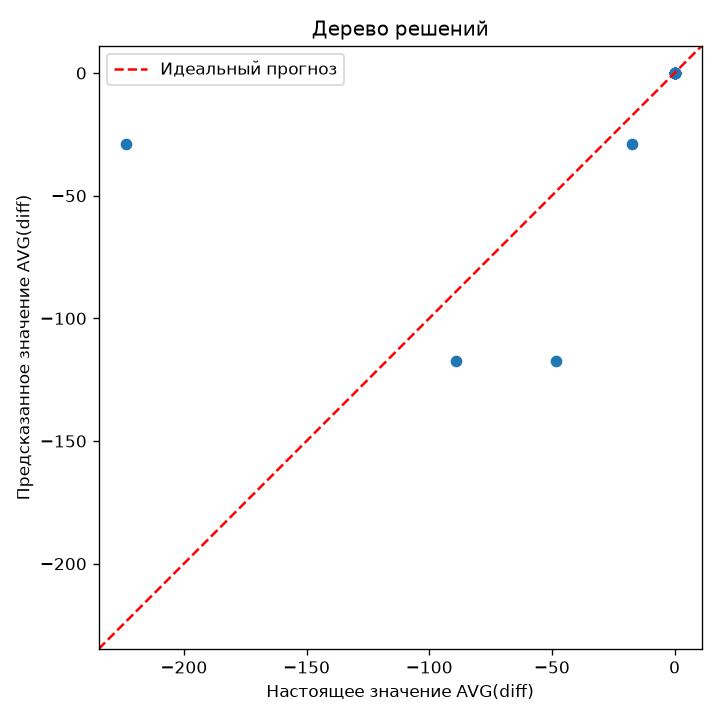

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(tree_test_df["actual"], tree_test_df["predicted"])
plt.xlabel("Настоящее значение AVG(diff)")
plt.ylabel("Предсказанное значение AVG(diff)")
plt.title("Дерево решений")
plt.plot(limits, limits, "r--", label="Идеальный прогноз")
plt.xlim(limits)
plt.ylim(limits)
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
forest_model = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=21)
forest_model.fit(X_train, y_train)
forest_pred = forest_model.predict(X_test)
forest_test_df = pd.DataFrame({
    "actual": y_test,
    "predicted": forest_pred
})
print("RMSE:", root_mean_squared_error(y_test, forest_pred))
forest_test_df


RMSE: 40.46444871014561


,actual,predicted
3,0.0,0.000000
19,-17.5,-47.261549
14,-48.5,-114.930366
45,-223.6,-82.395786
10,0.0,0.000000
54,0.0,0.000000
23,0.0,0.000000
29,0.0,0.000000
24,0.0,0.000000
13,-89.0,-119.993101


<prediction cell 20>:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


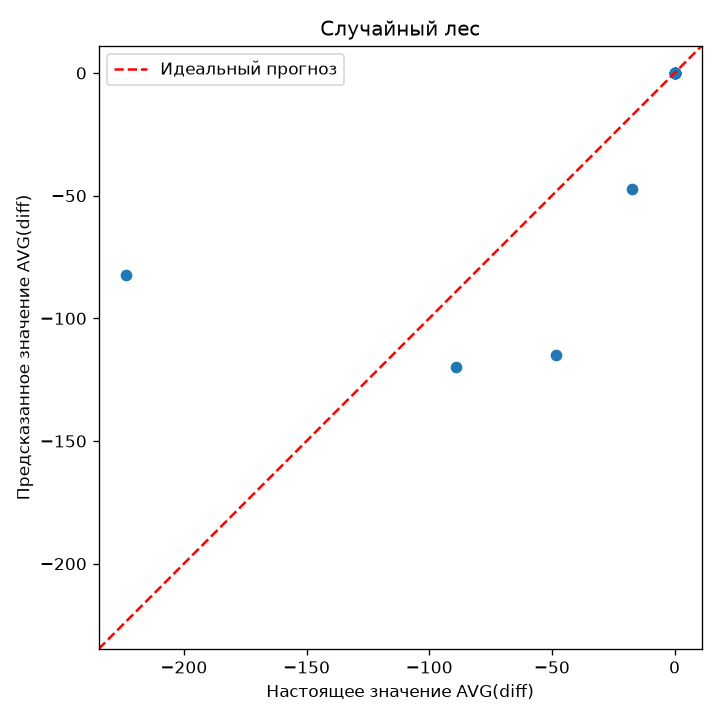

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(forest_test_df["actual"], forest_test_df["predicted"])
plt.xlabel("Настоящее значение AVG(diff)")
plt.ylabel("Предсказанное значение AVG(diff)")
plt.title("Случайный лес")
plt.plot(limits, limits, "r--", label="Идеальный прогноз")
plt.xlim(limits)
plt.ylim(limits)
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.tight_layout()
plt.show()


В идеальном случае все точки лежат на прямой y = x: предсказанные значения совпадают с фактическими. 
Чем ближе точки к этой прямой, тем меньше ошибки предсказаний.